# Data Exploration

Exploration of the [UC Merced Land Use dataset](http://weegee.vision.ucmerced.edu/datasets/landuse.html) used to train the Vision Transformer from [An Image is Worth 16x16 Words: Transformers for Image Recognition at Scale](https://arxiv.org/abs/2010.11929) (Dosovitskiy et al., 2020).

In this notebook I look at the classes and image resolutions, and drop the images that are not $256 \times 256$. The patch embedding cuts every image into the same grid of $N = HW / P^2$ patches, and the position embedding $\mathbf{E}_{pos} \in \mathbb{R}^{(N+1) \times D}$ from Eq. 1 has a fixed size, so all images need the same $H$ and $W$, divisible by $P$.

**Contents**
1. Setup
2. Data
3. Image resolutions
4. Dropping off-size images

## 1. Setup

In [1]:
import random
import shutil
from pathlib import Path

import cv2 as cv
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
DATA_PATH = Path("../data/")
RAW_IMAGES_PATH = DATA_PATH / "raw"
PROCESSED_IMAGES_PATH = DATA_PATH / "processed"

IMAGE_SIZE = 256  # H = W

In [3]:
def set_seed(seed: int = 42):
    """Seeds Python's random number generator so the sampled images are reproducible.

    Args:
        seed: Seed value passed to the generator.
    """
    random.seed(seed)

## 2. Data

The dataset contains aerial RGB images stored as `.tif` files, one folder per land-use class.

In [4]:
CLASSES = sorted(path.name for path in RAW_IMAGES_PATH.iterdir() if path.is_dir())
image_paths = sorted(RAW_IMAGES_PATH.glob("*/*.tif"))

print(f"There are {len(image_paths)} images in {len(CLASSES)} classes.")

There are 2100 images in 21 classes.


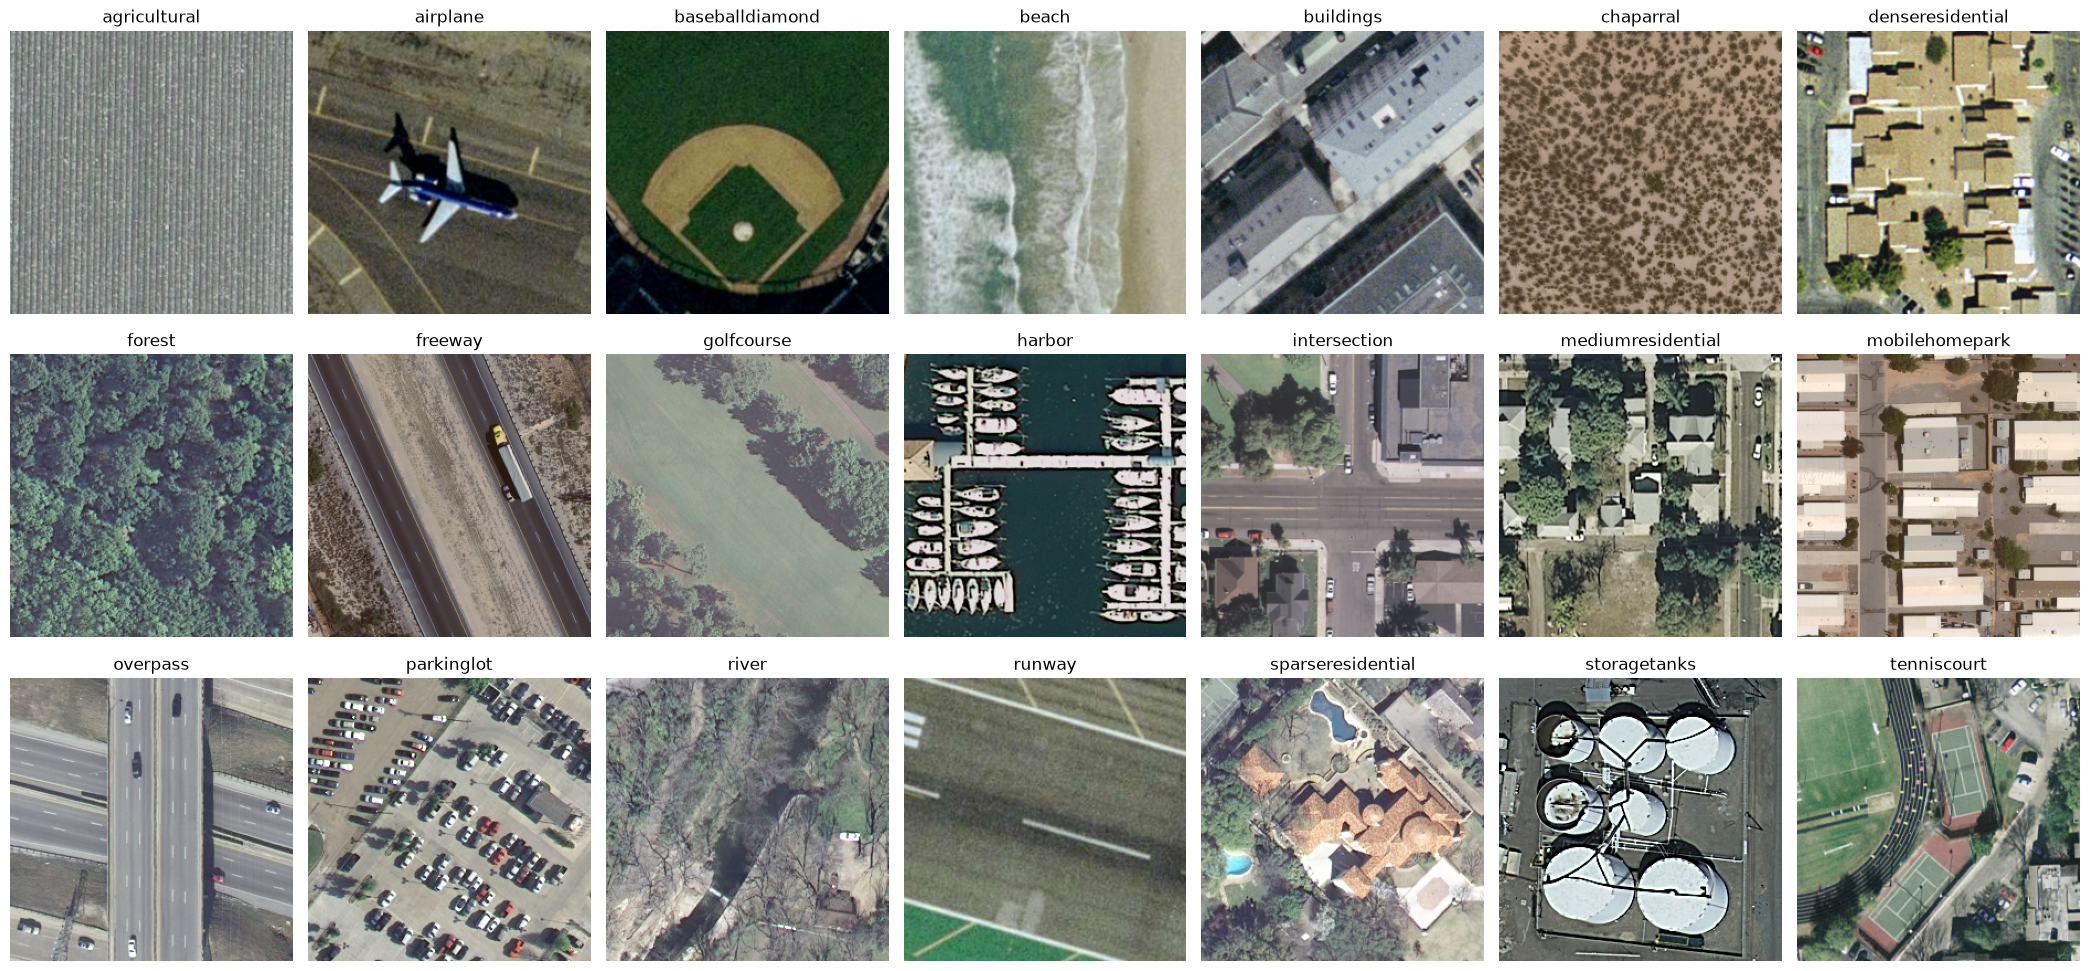

In [5]:
set_seed()

fig, axes = plt.subplots(3, 7, figsize=(21, 10))

for ax, class_name in zip(axes.flat, CLASSES):
    image_path = random.choice(sorted((RAW_IMAGES_PATH / class_name).glob("*.tif")))
    image = cv.cvtColor(cv.imread(str(image_path)), cv.COLOR_BGR2RGB)
    ax.imshow(image)
    ax.set_title(class_name)
    ax.axis("off")

plt.tight_layout()
plt.show()

## 3. Image resolutions

Reading every image gives its height, width and number of color channels.

In [6]:
records = []

for image_path in image_paths:
    height, width, channels = cv.imread(str(image_path)).shape
    records.append({"path": image_path, "class": image_path.parent.name, "height": height, "width": width, "channels": channels})

images_df = pd.DataFrame(records)
images_df.head()

,path,class,height,width,channels
0,../data/raw/agricultural/agricultural00.tif,agricultural,256,256,3
1,../data/raw/agricultural/agricultural01.tif,agricultural,256,256,3
2,../data/raw/agricultural/agricultural02.tif,agricultural,256,256,3
3,../data/raw/agricultural/agricultural03.tif,agricultural,256,256,3
4,../data/raw/agricultural/agricultural04.tif,agricultural,256,256,3


In [7]:
images_df.groupby(["height", "width", "channels"]).size().sort_values(ascending=False)

height  width  channels
256     256    3           2056
247     247    3              9
256     253    3              6
251     256    3              5
256     255    3              4
253     256    3              3
256     254    3              3
        252    3              2
249     256    3              2
254     256    3              2
256     250    3              2
        247    3              1
        249    3              1
247     256    3              1
256     242    3              1
255     256    3              1
257     257    3              1
dtype: int64

### 3.1 Off-size images

Most images are $256 \times 256$, but some are a few pixels smaller or larger in one or both dimensions.

In [8]:
is_off_size = (images_df["height"] != IMAGE_SIZE) | (images_df["width"] != IMAGE_SIZE)
off_size_df = images_df[is_off_size]

print(f"There are {len(off_size_df)} images that are not {IMAGE_SIZE}x{IMAGE_SIZE}.")
off_size_df["class"].value_counts()

There are 44 images that are not 256x256.


class
overpass             10
baseballdiamond       4
golfcourse            4
mobilehomepark        4
airplane              3
sparseresidential     3
storagetanks          3
harbor                2
parkinglot            2
river                 2
runway                2
tenniscourt           2
beach                 1
buildings             1
intersection          1
Name: count, dtype: int64

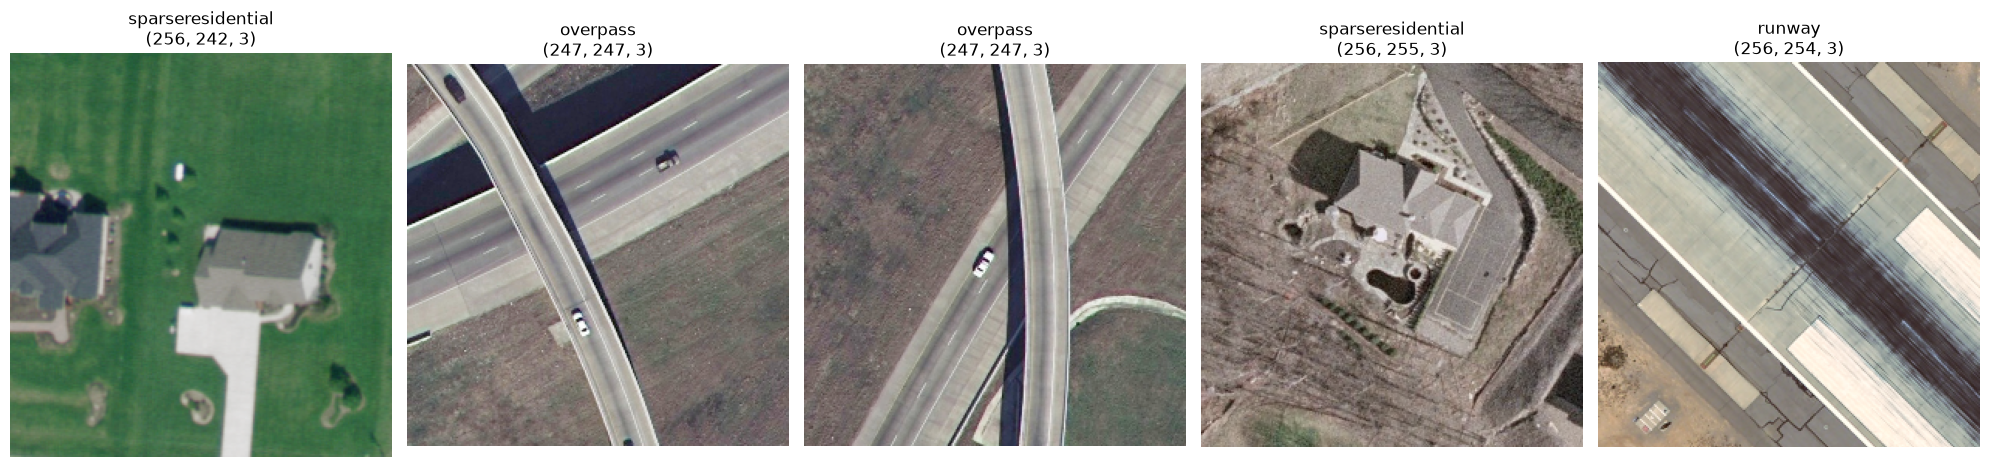

In [9]:
fig, axes = plt.subplots(1, 5, figsize=(20, 5))

for ax, (_, row) in zip(axes, off_size_df.sample(n=5, random_state=42).iterrows()):
    image = cv.cvtColor(cv.imread(str(row["path"])), cv.COLOR_BGR2RGB)
    ax.imshow(image)
    ax.set_title(f"{row['class']}\n{image.shape}")
    ax.axis("off")

plt.tight_layout()
plt.show()

## 4. Dropping off-size images

The off-size images are a small fraction of the dataset, so dropping them keeps every remaining image at its native resolution instead of resizing or padding. Classes are no longer perfectly balanced afterwards.

Keeping 2056 of 2100 images.


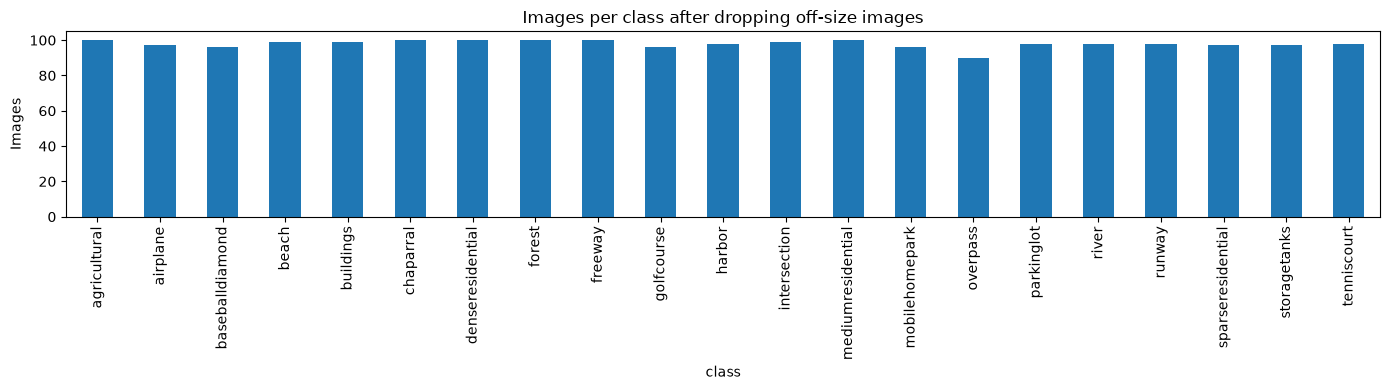

In [10]:
valid_df = images_df[~is_off_size]
class_counts = valid_df["class"].value_counts().sort_index()

print(f"Keeping {len(valid_df)} of {len(images_df)} images.")

fig, ax = plt.subplots(figsize=(14, 4))
class_counts.plot.bar(ax=ax)
ax.set_ylabel("Images")
ax.set_title("Images per class after dropping off-size images")

plt.tight_layout()
plt.show()

### 4.1 Saving the processed dataset

`data/raw/` stays untouched. The remaining images are copied to `data/processed/` with the same folder per class layout.

In [11]:
for image_path in valid_df["path"]:
    target_path = PROCESSED_IMAGES_PATH / image_path.parent.name / image_path.name
    target_path.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy2(image_path, target_path)

processed_count = len(list(PROCESSED_IMAGES_PATH.glob("*/*.tif")))
# Catches stale files left in data/processed/ by an earlier run with different filtering
assert processed_count == len(valid_df), f"processed image count mismatch: expected={len(valid_df)}, found={processed_count}"

print(f"Copied {processed_count} images to '{PROCESSED_IMAGES_PATH}'.")

Copied 2056 images to '../data/processed'.
